In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_PATH = ROOT_DIR / "dataset" / "raw" / "career_navigator_synthetic.csv"
REPORT_DIR = ROOT_DIR / "reports" / "eda"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATASET_PATH)

pd.set_option("display.max_columns", None)

print("Dataset loaded:", df.shape)

Dataset loaded: (15000, 49)


In [2]:
target_columns = [
    "placement_status",
    "career_readiness",
    "recommended_career_domain",
    "employability_score"
]

id_columns = ["student_id"]

feature_columns = [
    column for column in df.columns
    if column not in target_columns + id_columns
]

numerical_features = df[feature_columns].select_dtypes(include=np.number).columns.tolist()
categorical_features = df[feature_columns].select_dtypes(include=["object", "category"]).columns.tolist()

print("Total input features:", len(feature_columns))
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("\nCategorical columns:", categorical_features)

Total input features: 44
Numerical features: 41
Categorical features: 3

Categorical columns: ['education_level', 'degree', 'specialization']


C:\Users\DHRUV\AppData\Local\Temp\ipykernel_24560\3447446172.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df[feature_columns].select_dtypes(include=["object", "category"]).columns.tolist()


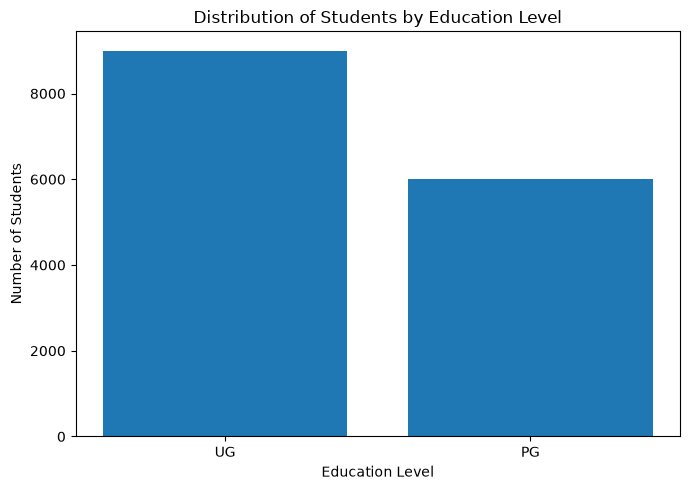

In [3]:
education_counts = df["education_level"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(education_counts.index, education_counts.values)
plt.title("Distribution of Students by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.savefig(REPORT_DIR / "education_distribution.png", dpi=300)
plt.show()

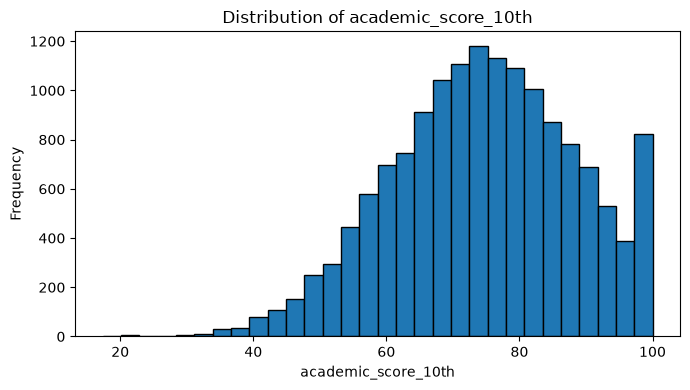

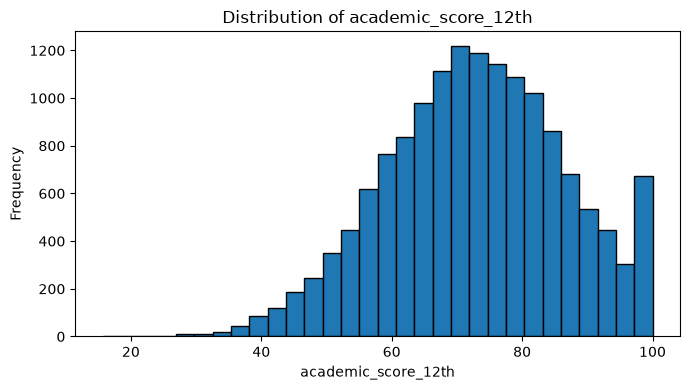

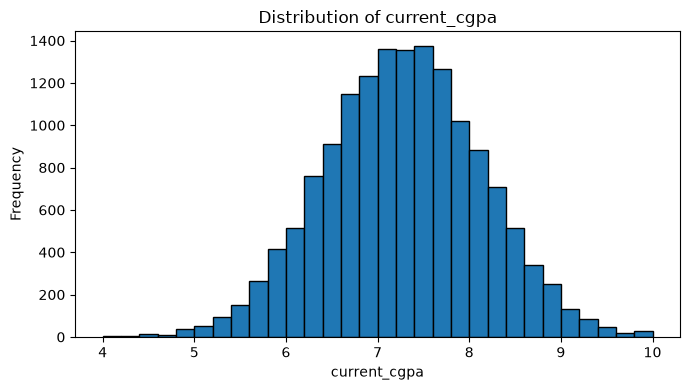

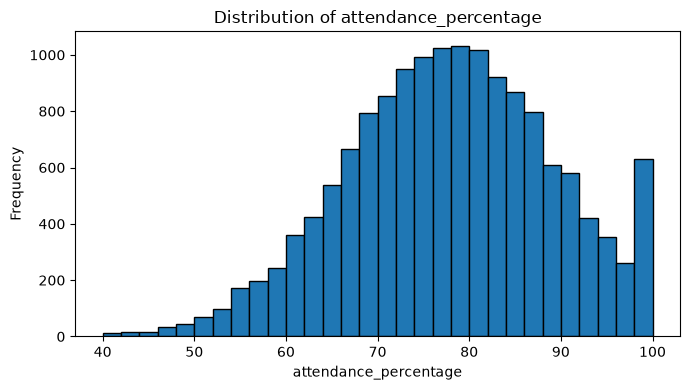

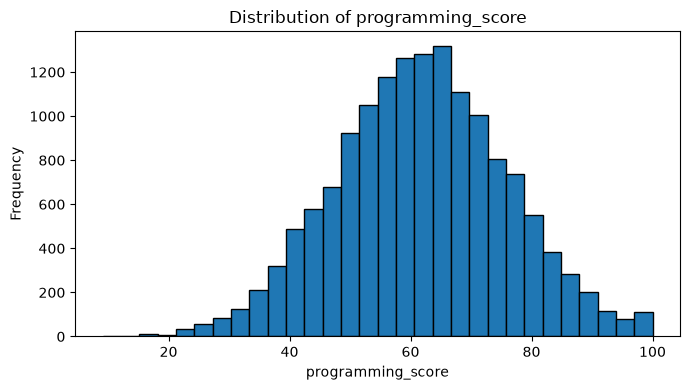

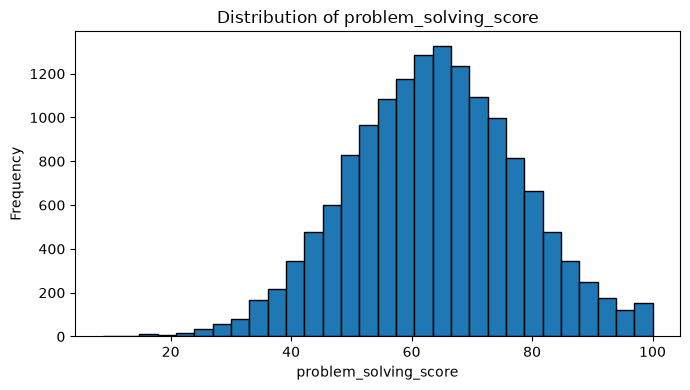

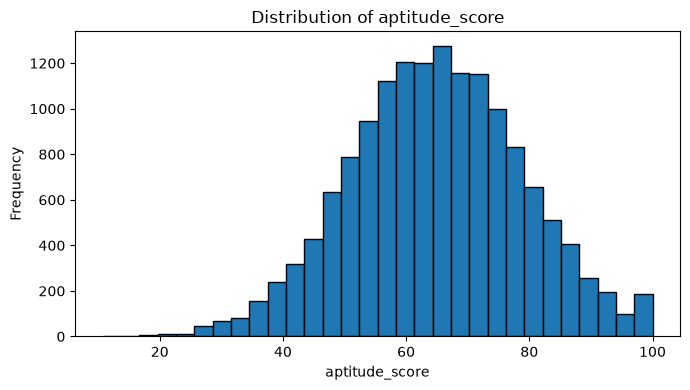

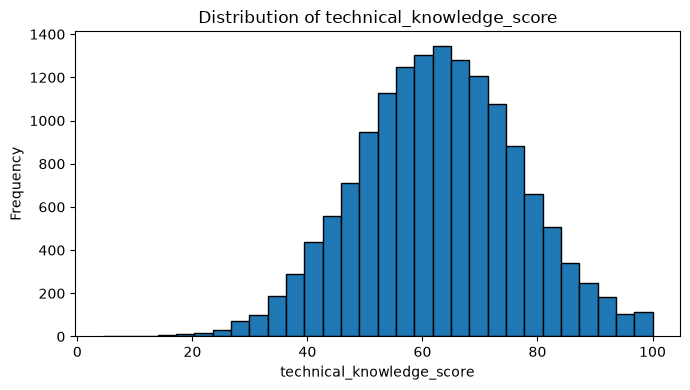

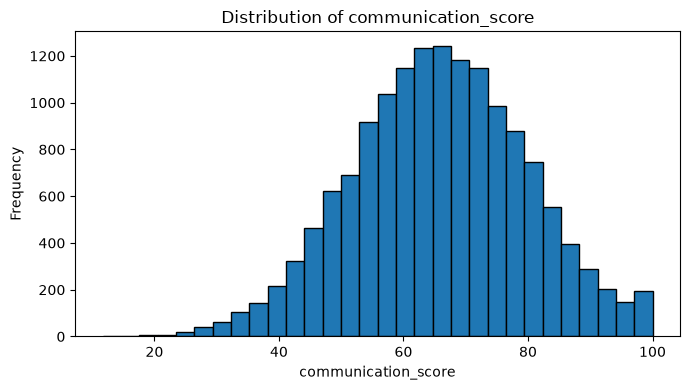

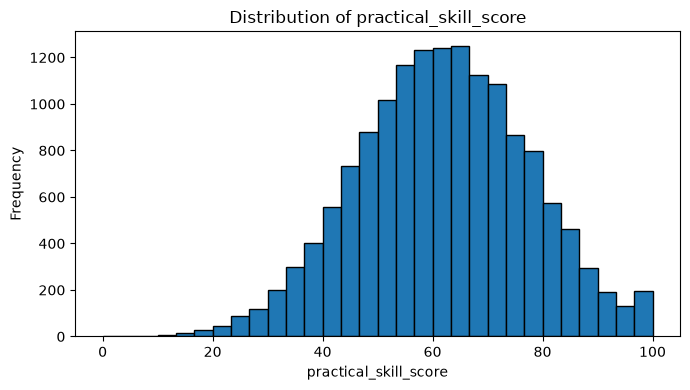

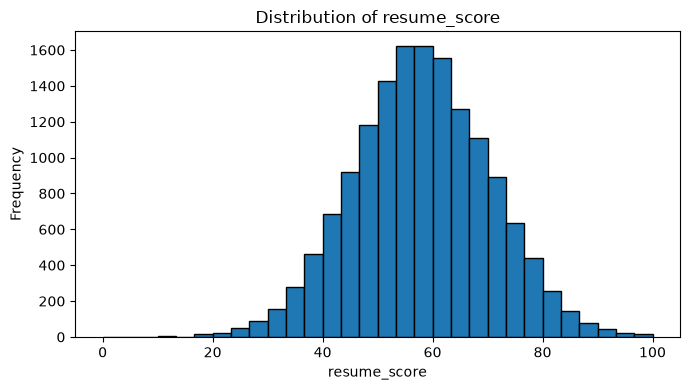

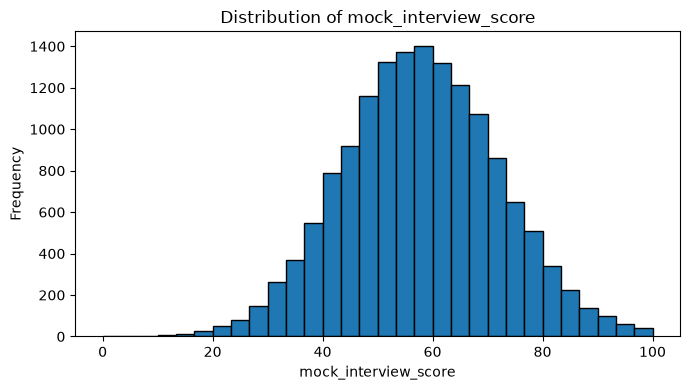

In [4]:
distribution_features = [
    "academic_score_10th",
    "academic_score_12th",
    "current_cgpa",
    "attendance_percentage",
    "programming_score",
    "problem_solving_score",
    "aptitude_score",
    "technical_knowledge_score",
    "communication_score",
    "practical_skill_score",
    "resume_score",
    "mock_interview_score"
]

for column in distribution_features:
    plt.figure(figsize=(7, 4))
    plt.hist(df[column].dropna(), bins=30, edgecolor="black")
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(REPORT_DIR / f"distribution_{column}.png", dpi=300)
    plt.show()

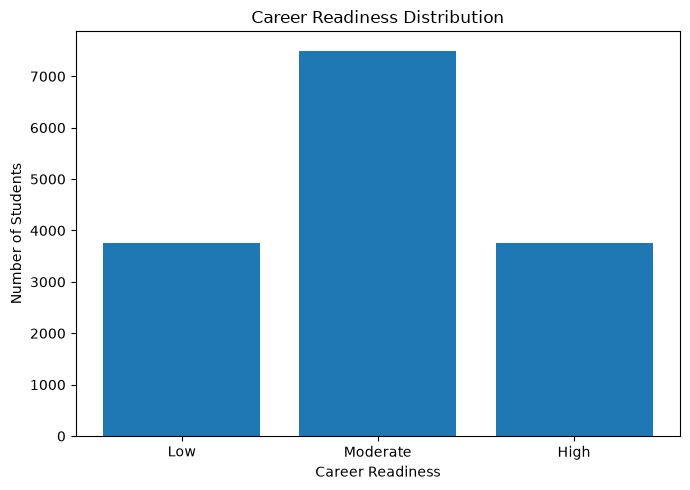

In [5]:
readiness_order = ["Low", "Moderate", "High"]
readiness_counts = df["career_readiness"].value_counts().reindex(readiness_order)

plt.figure(figsize=(7, 5))
plt.bar(readiness_counts.index, readiness_counts.values)
plt.title("Career Readiness Distribution")
plt.xlabel("Career Readiness")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.savefig(REPORT_DIR / "career_readiness_distribution.png", dpi=300)
plt.show()

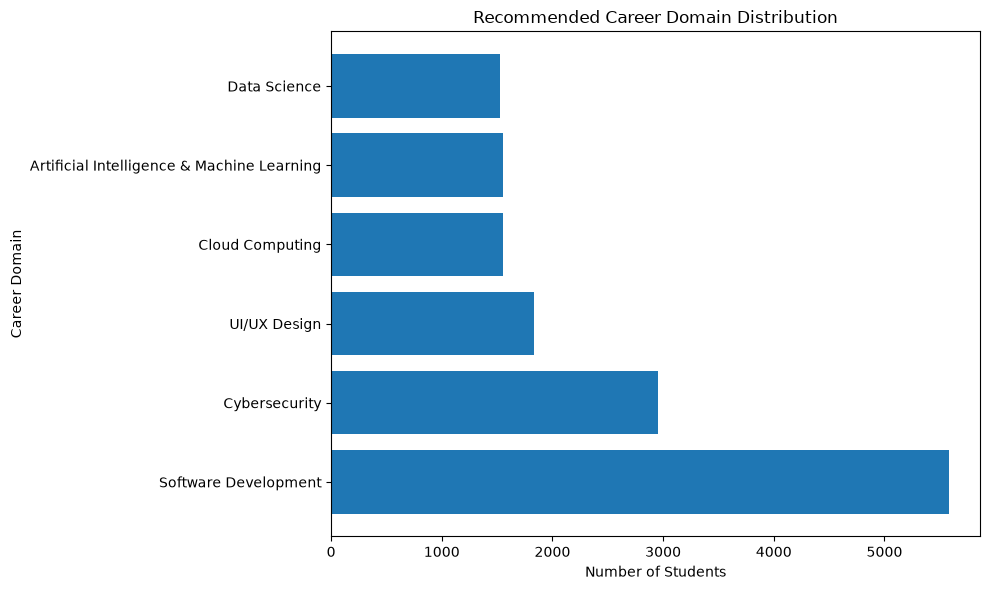

In [6]:
domain_counts = df["recommended_career_domain"].value_counts()

plt.figure(figsize=(10, 6))
plt.barh(domain_counts.index, domain_counts.values)
plt.title("Recommended Career Domain Distribution")
plt.xlabel("Number of Students")
plt.ylabel("Career Domain")
plt.tight_layout()
plt.savefig(REPORT_DIR / "career_domain_distribution.png", dpi=300)
plt.show()

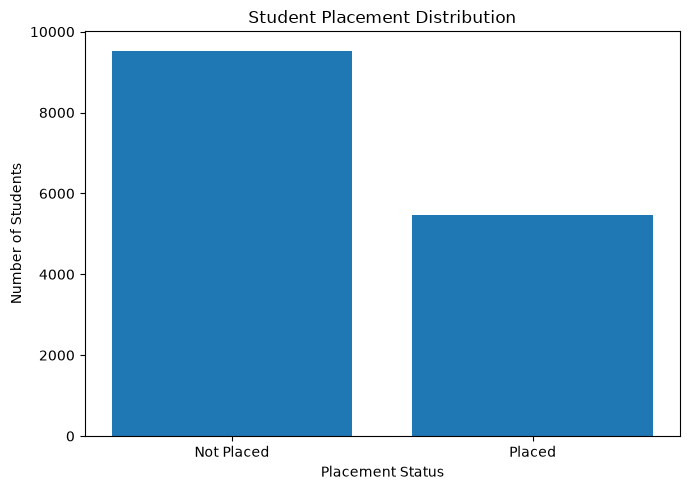

In [7]:
placement_labels = {0: "Not Placed", 1: "Placed"}
placement_counts = df["placement_status"].map(placement_labels).value_counts()

plt.figure(figsize=(7, 5))
plt.bar(placement_counts.index, placement_counts.values)
plt.title("Student Placement Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.savefig(REPORT_DIR / "placement_distribution.png", dpi=300)
plt.show()

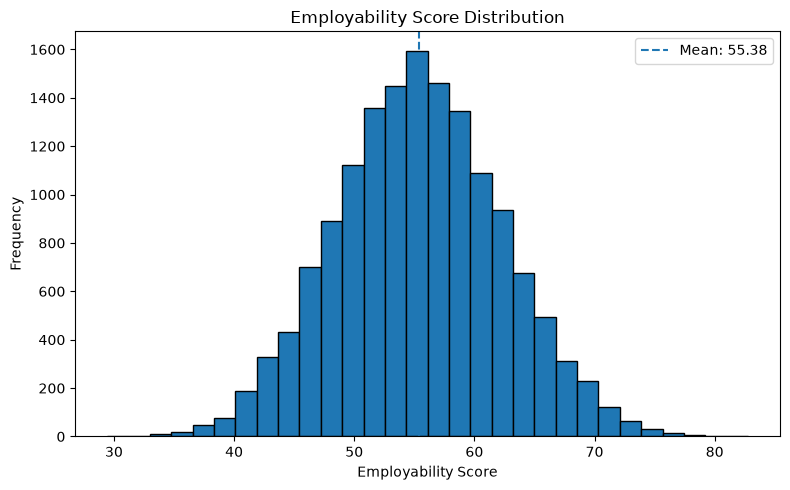

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(df["employability_score"], bins=30, edgecolor="black")
plt.axvline(df["employability_score"].mean(), linestyle="--",
            label=f"Mean: {df['employability_score'].mean():.2f}")
plt.title("Employability Score Distribution")
plt.xlabel("Employability Score")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.savefig(REPORT_DIR / "employability_distribution.png", dpi=300)
plt.show()

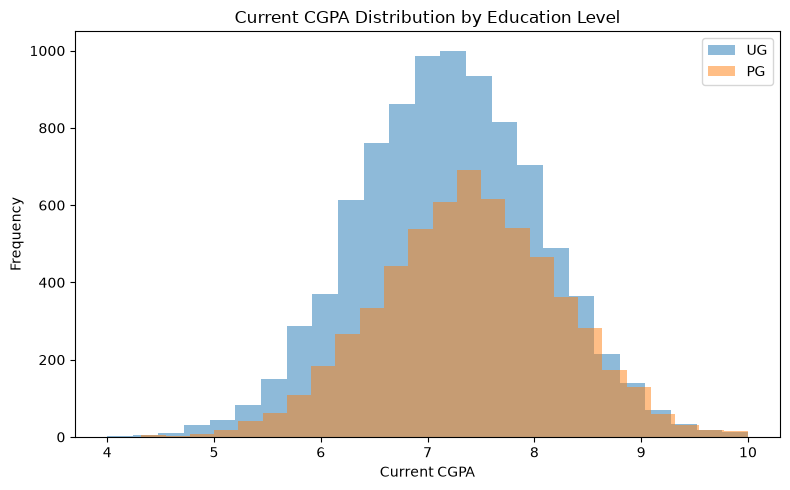

In [9]:
plt.figure(figsize=(8, 5))

for level in ["UG", "PG"]:
    subset = df[df["education_level"] == level]
    plt.hist(
        subset["current_cgpa"],
        bins=25,
        alpha=0.5,
        label=level
    )

plt.title("Current CGPA Distribution by Education Level")
plt.xlabel("Current CGPA")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.savefig(REPORT_DIR / "cgpa_by_education.png", dpi=300)
plt.show()

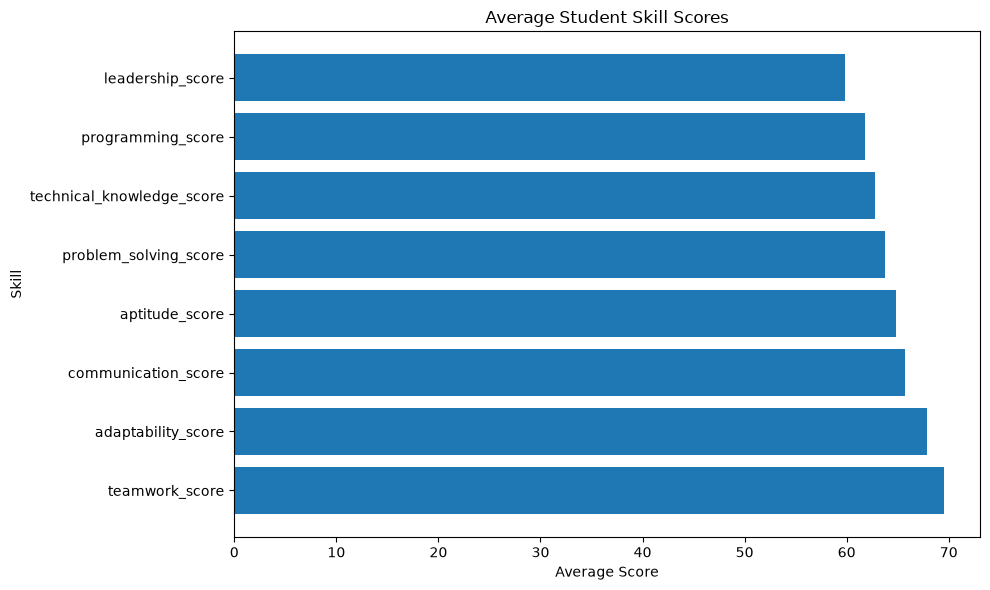

In [10]:
skill_columns = [
    "programming_score",
    "problem_solving_score",
    "aptitude_score",
    "technical_knowledge_score",
    "communication_score",
    "teamwork_score",
    "leadership_score",
    "adaptability_score"
]

skill_means = df[skill_columns].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(skill_means.index, skill_means.values)
plt.title("Average Student Skill Scores")
plt.xlabel("Average Score")
plt.ylabel("Skill")
plt.tight_layout()
plt.savefig(REPORT_DIR / "average_skill_scores.png", dpi=300)
plt.show()

In [11]:
correlation_columns = [
    column for column in numerical_features
    if column != "undergraduate_cgpa"
]

correlation_matrix = df[correlation_columns].corr()

display(correlation_matrix.round(2))

,study_year,academic_score_10th,academic_score_12th,current_cgpa,backlogs,attendance_percentage,academic_projects,major_projects,practical_skill_score,research_experience,training_hours,programming_score,problem_solving_score,aptitude_score,technical_knowledge_score,communication_score,teamwork_score,leadership_score,adaptability_score,internship_count,internship_duration_months,certifications_count,hackathon_participation,hackathon_wins,github_projects,resume_score,mock_interview_score,interview_preparation_hours,interest_ai_ml,interest_data_science,interest_software_dev,interest_cybersecurity,interest_cloud,interest_uiux,skill_ai_ml,skill_data_science,skill_software_dev,skill_cybersecurity,skill_cloud,skill_uiux
study_year,1.00,0.00,0.00,-0.05,0.01,-0.00,0.26,0.27,-0.01,-0.26,0.00,-0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.08,-0.07,-0.00,-0.01,-0.00,0.13,-0.01,0.00,0.01,-0.01,0.01,-0.00,0.00,0.01,-0.00,0.00,0.00,-0.01,-0.00,-0.00,-0.02
academic_score_10th,0.00,1.00,0.49,0.53,-0.11,0.37,-0.00,-0.00,0.07,-0.02,-0.01,0.23,0.24,0.50,0.23,0.11,0.12,0.13,0.11,0.00,-0.00,-0.02,0.00,-0.01,-0.00,0.12,0.12,0.01,-0.01,0.01,0.01,0.02,-0.02,0.00,0.22,0.32,0.16,0.22,0.20,0.12
academic_score_12th,0.00,0.49,1.00,0.54,-0.11,0.36,0.01,-0.01,0.07,-0.01,-0.01,0.23,0.23,0.49,0.22,0.11,0.12,0.12,0.12,0.00,-0.00,-0.01,-0.01,-0.01,0.00,0.12,0.13,0.01,-0.00,0.00,0.01,0.02,-0.02,0.01,0.22,0.32,0.16,0.21,0.20,0.12
current_cgpa,-0.05,0.53,0.54,1.00,-0.13,0.39,-0.02,-0.01,0.08,0.05,-0.00,0.25,0.25,0.53,0.25,0.12,0.13,0.13,0.12,0.03,0.02,0.01,-0.00,0.00,-0.01,0.12,0.13,0.01,0.00,-0.01,0.01,0.01,-0.02,0.00,0.24,0.34,0.18,0.23,0.21,0.12
backlogs,0.01,-0.11,-0.11,-0.13,1.00,-0.08,-0.00,-0.00,-0.01,-0.02,-0.00,-0.05,-0.06,-0.11,-0.06,-0.04,-0.02,-0.02,-0.03,0.01,0.01,-0.00,0.00,0.01,0.00,-0.03,-0.03,-0.00,0.00,0.01,0.02,-0.03,-0.01,-0.00,-0.06,-0.07,-0.04,-0.05,-0.05,-0.04
attendance_percentage,-0.00,0.37,0.36,0.39,-0.08,1.00,-0.01,0.00,0.05,-0.02,0.01,0.18,0.17,0.37,0.18,0.09,0.09,0.09,0.09,0.00,-0.00,0.00,0.00,0.01,-0.00,0.09,0.08,0.01,-0.01,-0.00,0.01,0.00,-0.01,0.01,0.16,0.23,0.12,0.16,0.14,0.08
academic_projects,0.26,-0.00,0.01,-0.02,-0.00,-0.01,1.00,0.06,-0.01,-0.08,0.00,-0.00,-0.00,-0.01,0.00,0.00,0.02,0.01,0.01,-0.04,-0.04,-0.01,0.00,-0.00,0.50,-0.01,0.01,0.01,-0.00,0.01,-0.00,-0.01,0.01,0.00,-0.00,0.01,-0.02,0.00,0.00,-0.00
major_projects,0.27,-0.00,-0.01,-0.01,-0.00,0.00,0.06,1.00,-0.01,-0.07,0.01,-0.02,-0.01,-0.00,-0.01,0.00,0.00,-0.01,0.00,-0.03,-0.03,-0.01,0.00,-0.00,0.04,-0.01,-0.00,0.00,0.01,0.00,-0.01,-0.00,0.02,-0.00,-0.02,-0.00,-0.02,-0.01,-0.02,-0.01
practical_skill_score,-0.01,0.07,0.07,0.08,-0.01,0.05,-0.01,-0.01,1.00,-0.00,-0.01,0.15,0.15,0.07,0.15,0.02,0.01,0.01,0.01,0.00,-0.00,0.00,0.00,0.01,-0.00,0.28,0.02,-0.00,0.01,-0.00,-0.00,0.01,-0.02,0.00,0.16,0.14,0.22,0.14,0.25,0.21
research_experience,-0.26,-0.02,-0.01,0.05,-0.02,-0.02,-0.08,-0.07,-0.00,1.00,-0.01,-0.02,-0.00,-0.01,-0.02,-0.01,-0.01,-0.00,0.00,0.08,0.08,-0.00,0.01,0.00,-0.04,-0.00,-0.00,-0.00,-0.00,-0.01,-0.00,-0.00,0.00,0.00,-0.01,-0.02,-0.01,-0.01,-0.02,-0.00


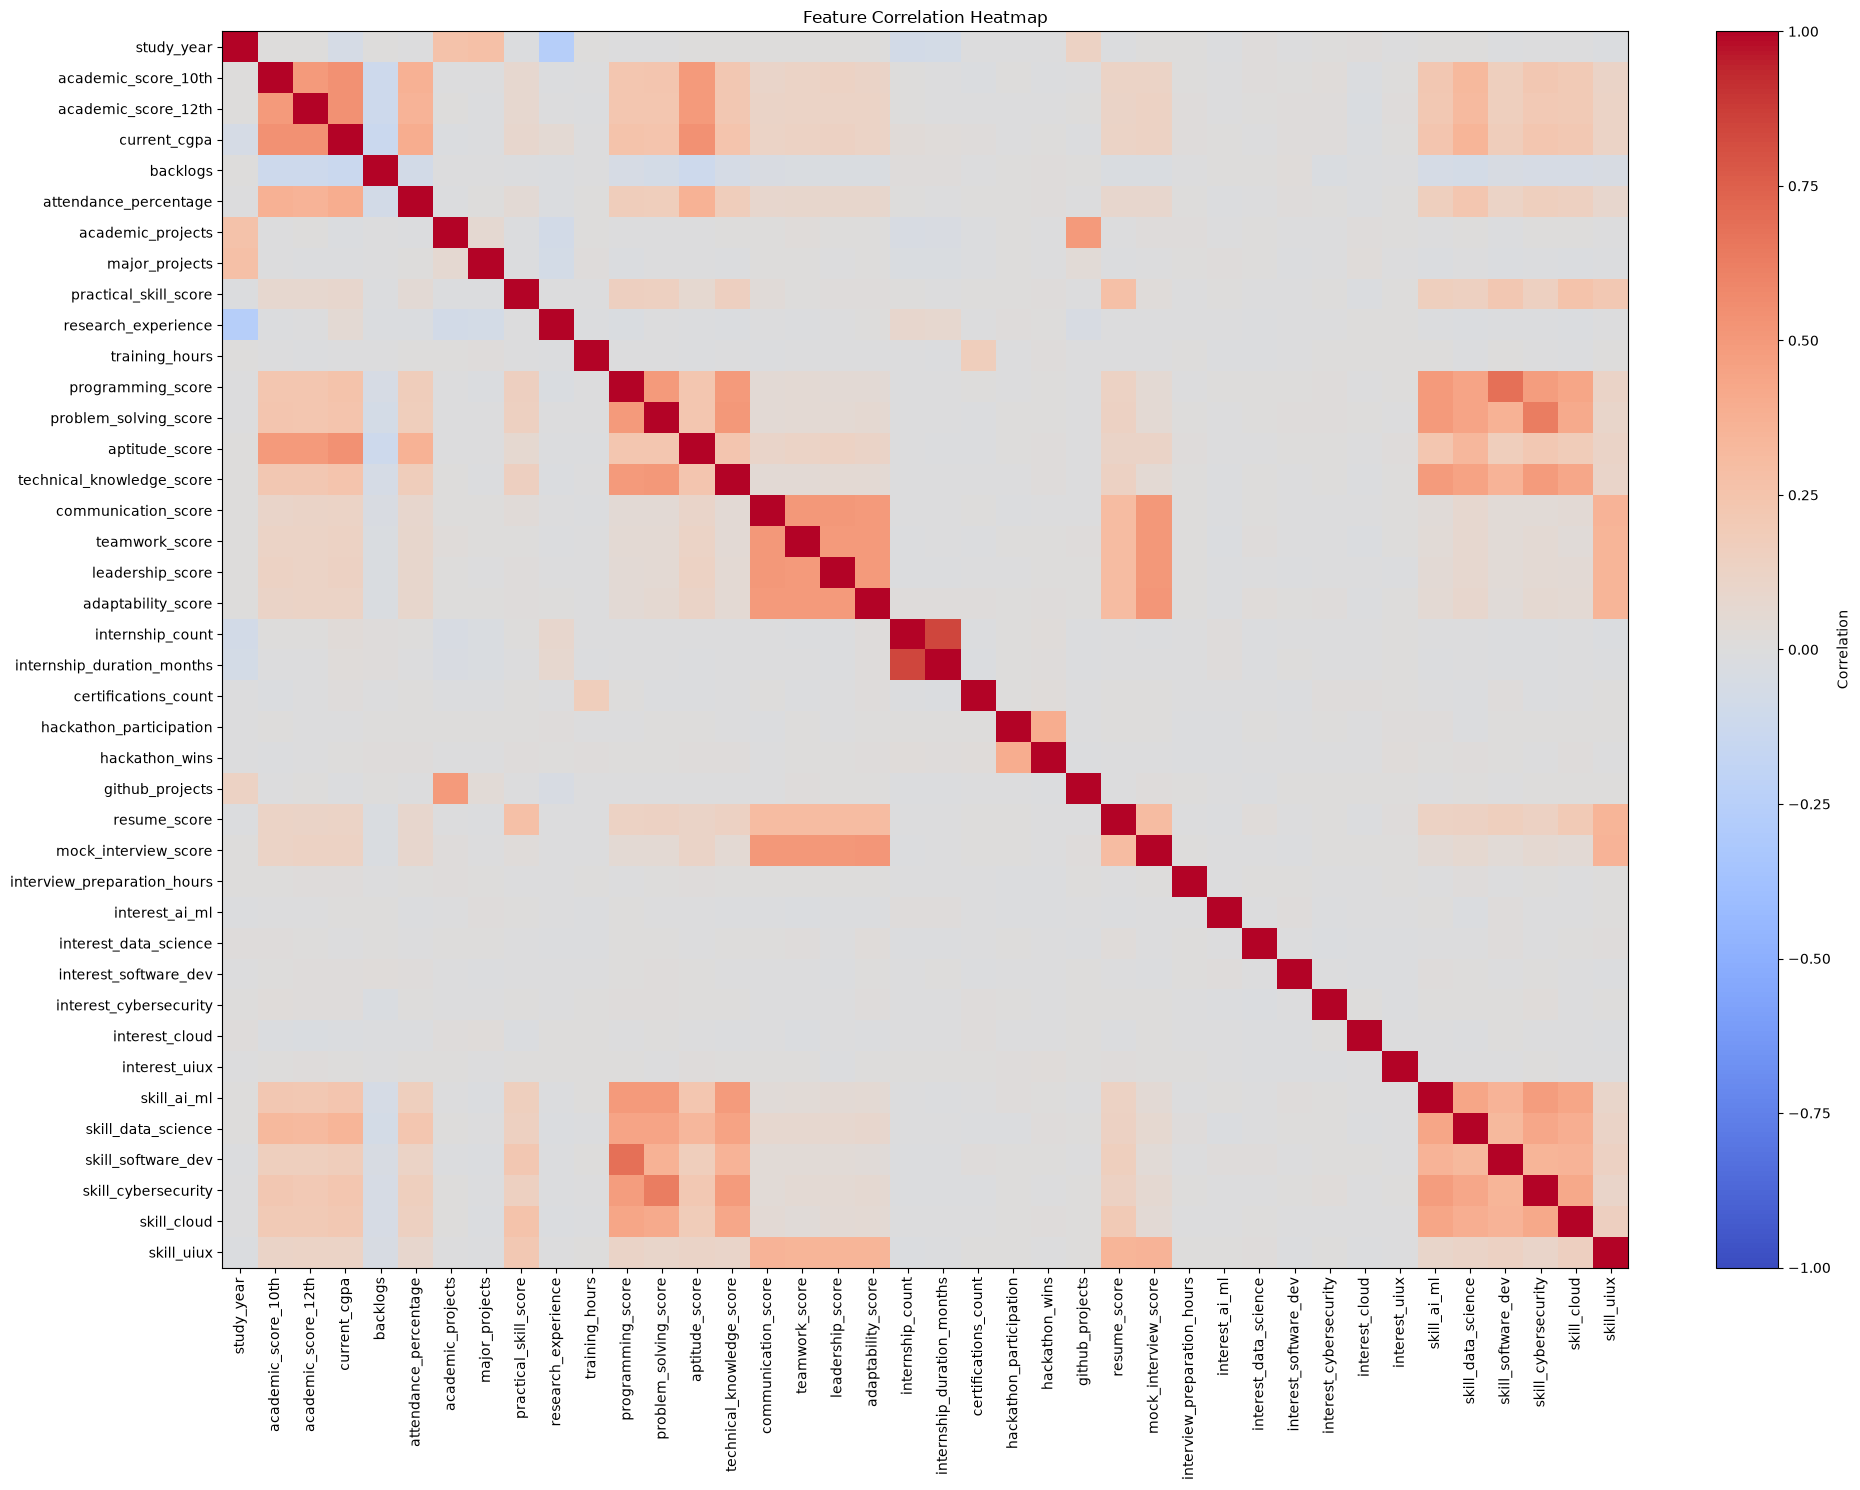

In [12]:
plt.figure(figsize=(20, 15))

plt.imshow(correlation_matrix, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig(REPORT_DIR / "correlation_heatmap.png", dpi=300)
plt.show()

placement_status,0,1
career_readiness,,
High,50.11,49.89
Low,74.61,25.39
Moderate,64.73,35.27


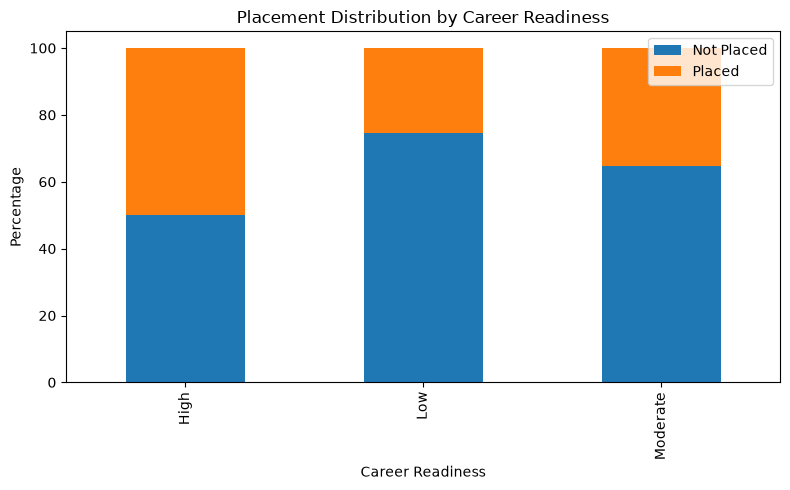

In [13]:
placement_readiness = pd.crosstab(
    df["career_readiness"],
    df["placement_status"],
    normalize="index"
) * 100

display(placement_readiness.round(2))

placement_readiness.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Placement Distribution by Career Readiness")
plt.xlabel("Career Readiness")
plt.ylabel("Percentage")
plt.legend(["Not Placed", "Placed"])
plt.tight_layout()
plt.savefig(REPORT_DIR / "placement_by_readiness.png", dpi=300)
plt.show()

,mean,median,std,count
recommended_career_domain,,,,
Data Science,55.65,55.46,7.08,1528
Artificial Intelligence & Machine Learning,55.58,55.28,6.94,1549
Cybersecurity,55.46,55.33,6.85,2958
UI/UX Design,55.40,55.51,7.01,1831
Software Development,55.28,55.28,6.86,5584
Cloud Computing,55.12,55.14,6.87,1550


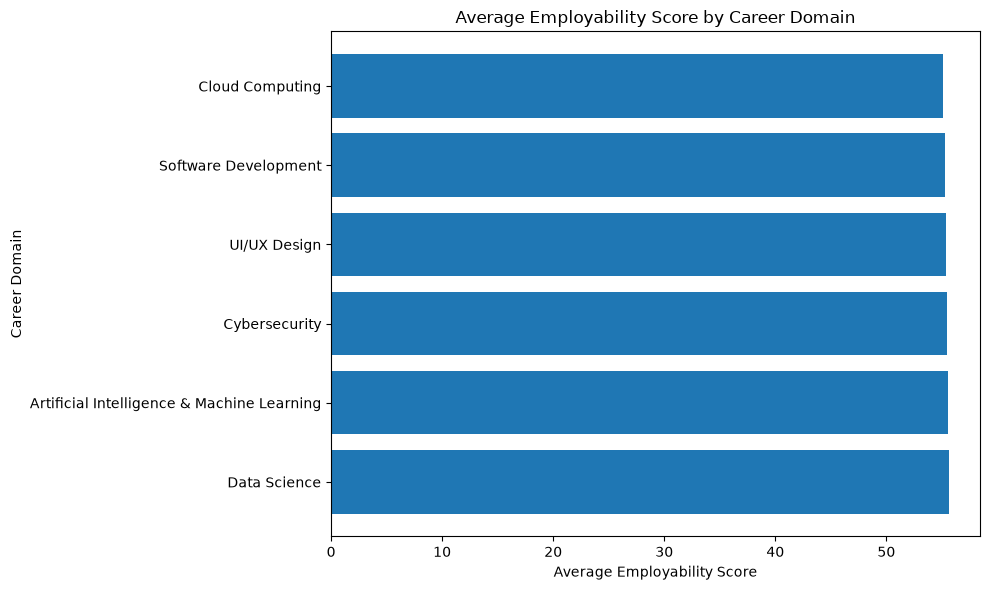

In [14]:
domain_employability = (
    df.groupby("recommended_career_domain")["employability_score"]
    .agg(["mean", "median", "std", "count"])
    .sort_values("mean", ascending=False)
)

display(domain_employability.round(2))

plt.figure(figsize=(10, 6))
plt.barh(
    domain_employability.index,
    domain_employability["mean"]
)

plt.title("Average Employability Score by Career Domain")
plt.xlabel("Average Employability Score")
plt.ylabel("Career Domain")
plt.tight_layout()
plt.savefig(REPORT_DIR / "employability_by_domain.png", dpi=300)
plt.show()

In [15]:
summary_path = REPORT_DIR / "eda_summary.txt"

with open(summary_path, "w", encoding="utf-8") as file:
    file.write("CAREER NAVIGATOR - EDA SUMMARY\n")
    file.write("=" * 60 + "\n\n")

    file.write(f"Dataset shape: {df.shape}\n")
    file.write(f"Input features: {len(feature_columns)}\n\n")

    file.write("Education distribution:\n")
    file.write(str(df["education_level"].value_counts()) + "\n\n")

    file.write("Placement distribution:\n")
    file.write(str(df["placement_status"].value_counts(normalize=True) * 100) + "\n\n")

    file.write("Career readiness distribution:\n")
    file.write(str(df["career_readiness"].value_counts(normalize=True) * 100) + "\n\n")

    file.write("Career domain distribution:\n")
    file.write(str(df["recommended_career_domain"].value_counts(normalize=True) * 100) + "\n\n")

    file.write("Employability score statistics:\n")
    file.write(str(df["employability_score"].describe()) + "\n\n")

    file.write("Feature correlations:\n")
    file.write(str(correlation_matrix.round(2)))

print("EDA summary saved:", summary_path)
print("EDA visualizations saved in:", REPORT_DIR)

EDA summary saved: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\reports\eda\eda_summary.txt
EDA visualizations saved in: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\reports\eda
